In [1]:
!pip uninstall -y datasets
!pip install -q datasets==3.6.0
!pip install -q transformers sentence-transformers gensim scikit-learn nltk stopwordsiso indic-nlp-library seaborn

Found existing installation: datasets 4.8.5
Uninstalling datasets-4.8.5:
  Successfully uninstalled datasets-4.8.5
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.3.0 which is incompatible.


In [2]:

import datasets
print("Datasets version:", datasets.__version__)

assert datasets.__version__ == "3.6.0"
print("Version verified successfully!")

Datasets version: 3.6.0
Version verified successfully!


In [3]:
import os, re, gc, json, random, warnings, unicodedata, textwrap
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)
warnings.filterwarnings("ignore")

from datasets import load_dataset
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation, NMF
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import normalize
from sentence_transformers import SentenceTransformer
from gensim.corpora import Dictionary
from gensim.models.coherencemodel import CoherenceModel
import stopwordsiso

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Random seed:", SEED)

NumPy: 2.4.6
Pandas: 2.2.3
Random seed: 42


In [4]:
def load_xlsum(language, target=500):
    # XL-Sum uses language configuration names such as "english" and "hindi".
    ds = load_dataset("csebuetnlp/xlsum", language, split="train")
    df = ds.to_pandas()
    required = "text"
    if required not in df.columns:
        raise ValueError(f"Expected 'text' column; found {list(df.columns)}")
    if "title" not in df.columns:
        df["title"] = ""
    df = df[["title", "text"]].copy()
    df["title"] = df["title"].fillna("").astype(str)
    df["text"] = df["text"].fillna("").astype(str)
    df["text"] = df["text"].str.replace(r"\s+", " ", regex=True).str.strip()
    df = df[df["text"].str.len() >= 120]
    df = df.drop_duplicates(subset=["text"]).reset_index(drop=True)
    n = min(target, len(df))
    return df.sample(n=n, random_state=SEED).reset_index(drop=True)

try:
    english_df = load_xlsum("english", 500)
    hindi_df = load_xlsum("hindi", 500)
    print("English usable documents:", len(english_df))
    print("Hindi usable documents:", len(hindi_df))
except Exception as e:
    raise RuntimeError(
        "XL-Sum could not be loaded. Check Colab internet access and the current "
        "Hugging Face dataset configuration. Do not report results until both corpora load."
    ) from e

display(english_df.head(3))
display(hindi_df.head(3))
assert len(english_df) >= 300 and len(hindi_df) >= 300, (
    "Assignment asks for at least 300 documents per language where feasible. "
    "The downloaded split has fewer usable records; inspect the dataset and document this limitation."
)

README.md:   0%|          | 0.00/14.6k [00:00<?, ?B/s]

xlsum.py:   0%|          | 0.00/4.55k [00:00<?, ?B/s]

The repository for csebuetnlp/xlsum contains custom code which must be executed to correctly load the dataset. You can inspect the repository content at https://hf.co/datasets/csebuetnlp/xlsum.
You can avoid this prompt in future by passing the argument `trust_remote_code=True`.

Do you wish to run the custom code? [y/N] y


data/english_XLSum_v2.0.tar.bz2: reconstructing file:   0%|          |  0.00B /  282MB            

data/english_XLSum_v2.0.tar.bz2: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

... (6 outputs left out)

Generating validation split: 0 examples [00:00, ? examples/s]

English usable documents: 500
Hindi usable documents: 500


,title,text
0,UKIP leadership: What does Gareth Bennett's el...,By David DeansBBC News That was where UKIP cho...
1,EE rushes to fix broadband box security risk,"Scott Helme said the vulnerability made ""remot..."
2,Gangs and drugs fuelling upsurge in prison vio...,"By Danny ShawHome affairs correspondent, BBC N..."


,title,text
0,'ट्रंप की नीतियां धर्मांधता से कम नहीं',अमरीका में राष्ट्रपति पद की उम्मीदवारी हासिल क...
1,"छत्तीसगढ़ चुनाव: रमन सिंह बोले, 'हारने पर कांग...",विधानसभा की 90 में से 18 सीटों पर इस महीने की ...
2,अमरीका की पोल खोलने वाले स्नोडेन की नई नौकरी,अमरीका की ख़ुफ़िया एजेंसी के पूर्व कर्मचारी स्...


In [5]:
dataset_summary = pd.DataFrame([
    {"Language":"English", "Dataset":"XL-Sum", "Source":"https://huggingface.co/datasets/csebuetnlp/xlsum",
     "Script":"Latin", "Documents":len(english_df), "Selection":"Train split; text length >=120 chars; deduplicated; random sample"},
    {"Language":"Hindi", "Dataset":"XL-Sum", "Source":"https://huggingface.co/datasets/csebuetnlp/xlsum",
     "Script":"Devanagari", "Documents":len(hindi_df), "Selection":"Train split; text length >=120 chars; deduplicated; random sample"},
    {"Language":"English-Hindi", "Dataset":"OPUS-100", "Source":"https://huggingface.co/datasets/Helsinki-NLP/opus-100",
     "Script":"Latin + Devanagari", "Documents":"20 pairs used below", "Selection":"First 20 usable parallel pairs from test split"}
])
display(dataset_summary)

,Language,Dataset,Source,Script,Documents,Selection
0,English,XL-Sum,https://huggingface.co/datasets/csebuetnlp/xlsum,Latin,500,Train split; text length >=120 chars; deduplic...
1,Hindi,XL-Sum,https://huggingface.co/datasets/csebuetnlp/xlsum,Devanagari,500,Train split; text length >=120 chars; deduplic...
2,English-Hindi,OPUS-100,https://huggingface.co/datasets/Helsinki-NLP/o...,Latin + Devanagari,20 pairs used below,First 20 usable parallel pairs from test split


In [6]:
import nltk
nltk.download("stopwords", quiet=True)
from nltk.corpus import stopwords as nltk_stopwords

EN_STOP = set(nltk_stopwords.words("english"))
HI_STOP = set(stopwordsiso.stopwords("hi") or [])

# Additional common function words; inspect and adjust for the selected corpus if necessary.
HI_STOP |= set("और है हैं था थी थे को के की का में से पर यह वह एक इस उस तथा लेकिन".split())

TOKEN_PATTERNS = {
    "en": re.compile(r"[a-z]+(?:'[a-z]+)?", re.IGNORECASE),
    # Devanagari letters and combining marks; keeps native script.
    "hi": re.compile(r"[\u0900-\u097F]+")
}

def preprocess(text, lang):
    text = unicodedata.normalize("NFC", str(text)).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    pattern = TOKEN_PATTERNS[lang]
    tokens = pattern.findall(text)
    stops = EN_STOP if lang == "en" else HI_STOP
    tokens = [t for t in tokens if len(t) > 1 and t not in stops]
    return tokens

english_df["tokens"] = english_df["text"].apply(lambda x: preprocess(x, "en"))
hindi_df["tokens"] = hindi_df["text"].apply(lambda x: preprocess(x, "hi"))
english_df = english_df[english_df["tokens"].map(len) >= 5].reset_index(drop=True)
hindi_df = hindi_df[hindi_df["tokens"].map(len) >= 5].reset_index(drop=True)

preprocess_summary = pd.DataFrame([
    {"Language":"English", "Documents after filtering":len(english_df),
     "Mean tokens/document":round(english_df.tokens.map(len).mean(),2),
     "Unique tokens":len(set(t for row in english_df.tokens for t in row)),
     "Stopword source":"NLTK English"},
    {"Language":"Hindi", "Documents after filtering":len(hindi_df),
     "Mean tokens/document":round(hindi_df.tokens.map(len).mean(),2),
     "Unique tokens":len(set(t for row in hindi_df.tokens for t in row)),
     "Stopword source":"stopwordsiso Hindi + small manually listed set"}
])
display(preprocess_summary)
print("English token sample:", english_df.tokens.iloc[0][:25])
print("Hindi token sample:", hindi_df.tokens.iloc[0][:25])
print("Hindi sample retains Devanagari:",
      any("\u0900" <= ch <= "\u097f" for ch in " ".join(hindi_df.tokens.iloc[0])))

,Language,Documents after filtering,Mean tokens/document,Unique tokens,Stopword source
0,English,500,255.20,17832,NLTK English
1,Hindi,500,279.19,16616,stopwordsiso Hindi + small manually listed set


English token sample: ['david', 'deansbbc', 'news', 'ukip', 'chose', 'hold', 'assembly', 'leadership', 'election', 'count', 'headquarters', 'building', 'near', 'market', 'town', 'newton', 'abbot', 'devon', 'incumbent', 'leader', 'caroline', 'jones', 'candidate', 'event', 'gareth']
Hindi token sample: ['अमरीका', 'राष्ट्रपति', 'पद', 'उम्मीदवारी', 'हासिल', 'ट्रंप', 'रिपब्लिकन', 'पार्टी', 'रेस', 'ज़ैद', 'राद', 'अल', 'हुसैन', 'ट्रंप', 'नाम', 'बिना', 'टॉर्चर', 'समर्थन', 'मुसलमानों', 'प्रति', 'नीतियों', 'ज़िक्र', 'कट्टरपंथ', 'सशक्त', 'नेतृत्व']
Hindi sample retains Devanagari: True


In [7]:
def make_dictionary(token_lists):
    dictionary = Dictionary(token_lists)
    dictionary.filter_extremes(no_below=3, no_above=0.80, keep_n=8000)
    corpus = [dictionary.doc2bow(tokens) for tokens in token_lists]
    return dictionary, corpus

def topic_words_from_gensim(model, n=10):
    return [[w for w, _ in model.show_topic(k, topn=n)] for k in range(model.num_topics)]

def fit_gensim_lda(token_lists, num_topics=5):
    dictionary, corpus = make_dictionary(token_lists)
    model = __import__("gensim").models.LdaModel(
        corpus=corpus, id2word=dictionary, num_topics=num_topics,
        random_state=SEED, passes=8, iterations=100,
        alpha="auto", eta="auto", minimum_probability=0
    )
    topics = topic_words_from_gensim(model, 10)
    coherence = CoherenceModel(
        topics=topics, texts=token_lists, dictionary=dictionary, coherence="c_v"
    ).get_coherence()
    return model, dictionary, corpus, topics, float(coherence)

en_lda, en_dict, en_bow, en_topics, en_cv = fit_gensim_lda(english_df.tokens.tolist(), 5)
hi_lda, hi_dict, hi_bow, hi_topics, hi_cv = fit_gensim_lda(hindi_df.tokens.tolist(), 5)

def show_topics(topics, language):
    print("\n", language, "LDA topics (top 10 words)")
    for i, words in enumerate(topics, 1):
        print(f"Topic {i}: " + ", ".join(words))

show_topics(en_topics, "ENGLISH")
show_topics(hi_topics, "HINDI")
print(f"English c_v coherence: {en_cv:.4f}")
print(f"Hindi c_v coherence:   {hi_cv:.4f}")


 ENGLISH LDA topics (top 10 words)
Topic 1: says, people, new, would, one, also, first, mr, bbc, time
Topic 2: mr, would, year, government, uk, also, people, new, one, time
Topic 3: us, also, says, mr, uk, would, people, government, year, police
Topic 4: mr, would, government, uk, also, wales, minister, new, school, ms
Topic 5: people, year, would, one, mr, also, like, years, two, time

 HINDI LDA topics (top 10 words)
Topic 1: पुलिस, वो, गए, लोगों, रही, गई, अब, लोग, बीबीसी, साल
Topic 2: पार्टी, वो, सरकार, उन्होंने, कांग्रेस, चुनाव, मैं, रही, क्या, बात
Topic 3: भारत, लोगों, उन्होंने, अमरीका, सरकार, चीन, गए, वो, बीबीसी, बीच
Topic 4: भारत, टीम, उन्होंने, क्रिकेट, वो, मैच, गई, लोगों, टेस्ट, साल
Topic 5: वो, उन्होंने, साल, काम, कहना, सरकार, हमें, रही, लोगों, बीबीसी
English c_v coherence: 0.3215
Hindi c_v coherence:   0.3773


In [8]:
# Human-readable labels assigned after inspecting the Q1 topic words and representative articles.
# Some topics are intentionally labelled as mixed/general where their top words overlap.

en_topic_labels = {
    1: "General News and Public Affairs",
    2: "UK Government and National Affairs",
    3: "Politics, Policing and Public Policy",
    4: "UK Government, Wales and Education",
    5: "Society and Contemporary Issues"
}

hi_topic_labels = {
    1: "General News and Public Safety (Mixed Topic)",
    2: "Indian Politics, Elections and Political History",
    3: "International Relations and Geopolitics",
    4: "Indian Cricket and Sports",
    5: "General Social, Economic and Work-related News"
}

topic_label_table = pd.DataFrame([
    {"Language":"English","Topic":i+1,"Top words":", ".join(w),"Human label":en_topic_labels[i+1]}
    for i,w in enumerate(en_topics)
] + [
    {"Language":"Hindi","Topic":i+1,"Top words":", ".join(w),"Human label":hi_topic_labels[i+1]}
    for i,w in enumerate(hi_topics)
])
display(topic_label_table)

print("\nInterpretation note:")
print("English topics 1 and 5, and Hindi topics 1 and 5, contain several broad/general terms.")
print("Hindi Topic 4 is the clearest domain-specific topic because भारत, टीम, क्रिकेट, मैच and टेस्ट occur together.")
print("Hindi Topic 2 is supported by पार्टी, सरकार, कांग्रेस and चुनाव.")
print("Labels are concise interpretations of the top words and representative documents, not ground-truth classes.")

,Language,Topic,Top words,Human label
0,English,1,"says, people, new, would, one, also, first, mr...",General News and Public Affairs
1,English,2,"mr, would, year, government, uk, also, people,...",UK Government and National Affairs
2,English,3,"us, also, says, mr, uk, would, people, governm...","Politics, Policing and Public Policy"
3,English,4,"mr, would, government, uk, also, wales, minist...","UK Government, Wales and Education"
4,English,5,"people, year, would, one, mr, also, like, year...",Society and Contemporary Issues
5,Hindi,1,"पुलिस, वो, गए, लोगों, रही, गई, अब, लोग, बीबीसी...",General News and Public Safety (Mixed Topic)
6,Hindi,2,"पार्टी, वो, सरकार, उन्होंने, कांग्रेस, चुनाव, ...","Indian Politics, Elections and Political History"
7,Hindi,3,"भारत, लोगों, उन्होंने, अमरीका, सरकार, चीन, गए,...",International Relations and Geopolitics
8,Hindi,4,"भारत, टीम, उन्होंने, क्रिकेट, वो, मैच, गई, लोग...",Indian Cricket and Sports
9,Hindi,5,"वो, उन्होंने, साल, काम, कहना, सरकार, हमें, रही...","General Social, Economic and Work-related News"



Interpretation note:
English topics 1 and 5, and Hindi topics 1 and 5, contain several broad/general terms.
Hindi Topic 4 is the clearest domain-specific topic because भारत, टीम, क्रिकेट, मैच and टेस्ट occur together.
Hindi Topic 2 is supported by पार्टी, सरकार, कांग्रेस and चुनाव.
Labels are concise interpretations of the top words and representative documents, not ground-truth classes.


In [9]:
def representative_docs(lda_model, dictionary, df, n_topics=5, per_topic=2):
    rows=[]
    for doc_id, tokens in enumerate(df.tokens.tolist()):
        bow = dictionary.doc2bow(tokens)
        if not bow:
            continue
        dist = sorted(lda_model.get_document_topics(bow), key=lambda x:x[1], reverse=True)
        topic_id, prob = dist[0]
        rows.append((topic_id, prob, doc_id))
    rows = pd.DataFrame(rows, columns=["topic","probability","doc_id"])
    out=[]
    for topic_id in range(n_topics):
        subset=rows[rows.topic==topic_id].nlargest(per_topic,"probability")
        for _,r in subset.iterrows():
            d=df.iloc[int(r.doc_id)]
            out.append({"Topic":topic_id+1,"Probability":round(float(r.probability),3),
                        "Title":d.title[:160],"Document excerpt":d.text[:500]})
    return pd.DataFrame(out)

display(representative_docs(en_lda,en_dict,english_df))
display(representative_docs(hi_lda,hi_dict,hindi_df))

,Topic,Probability,Title,Document excerpt
0,1,1.000,The Russell Prize 2019: A celebration of the y...,Amol RajanMedia editor@amolrajanon Twitter You...
1,1,0.999,Community volunteers with speed guns strike ba...,"By Dougal ShawWorld Hacks, BBC News ""My daught..."
2,2,1.000,Grenfell Inquiry: What five reports reveal,Professor Niamh Nic Daeid: Cause and spread of...
3,2,0.999,Covid-19: Critical care wards full in hospital...,By Rob EnglandBBC News It comes as hospital wa...
4,3,1.000,Families of Yemen bus strike victims despair a...,"By Sumaya BakhshBBC Monitoring The coalition, ..."
5,3,0.999,What motivates communities to buy land they li...,By Steven McKenzieBBC Scotland Highlands and I...
6,4,1.000,Week ahead in Parliament,Mark D'ArcyParliamentary correspondent Theresa...
7,4,0.999,MPs voting on May's Brexit strategy,They have rejected a Labour call for another v...
8,5,1.000,Is it OK if someone wants to live for years on...,A large bulky object wrapped in a bright blue ...
9,5,1.000,The Californian district attorney with a uniqu...,By James Clayton BBC News Chesa Boudin was ele...


,Topic,Probability,Title,Document excerpt
0,1,1.000,कोरोना वायरस से टूट रही बॉलीवुड की कमर,जबकि इन 17 फिल्मों में से एक ऋतिक रोशन की 'वार...
1,1,1.000,राजीव गांधी: वो धमाका जिसने उन्हें मार डाला,"""अगर ऐसा हो जाता है तो दुनिया की कोई भी ताक़त ..."
2,2,1.000,मैं नास्तिक क्यों हूँ: भगत सिंह,"***************** प्रत्येक मनुष्य को, जो विकास..."
3,2,1.000,"'जिन्ना को मालूम था, गवर्नर जनरल बनने से क्या ...",बाद में जब बांग्लादेश की मुक्ति का आंदोलन छिड़...
4,3,1.000,ईरान के ख़िलाफ़ इसराइल के ख़ुफ़िया ऑपरेशन कितन...,हालांकि वो अब भी अपने इस रुख़ पर क़ायम है कि उ...
5,3,1.000,भारत-चीन सीमा विवाद: साल भर बाद कहां तक पहुंचे...,इसी साल नौ अप्रैल को दोनों देशों के आला सैन्य ...
6,4,1.000,अंफान तूफान: ओडिशा और पश्चिम बंगाल के लिए बना ...,भारतीय मौसम विभाग (आईएमडी) का कहना है कि तूफान...
7,4,0.999,शुभमन गिल: पहलवान के ख़ानदान का पहला टेस्ट क्र...,इसके बाद वे भारतीय टीम की ओर से वनडे टीम में श...
8,5,1.000,बाकी दुनिया के मुक़ाबले अमीर कैसे हैं नॉर्वे क...,"ये कोई नई बात नहीं कि अमरीका, ब्रिटेन और दूसरे..."
9,5,1.000,कोरोना वायरस: किन हालात में काम कर रहे हैं भार...,"हेलो मिस्टर प्रधानमंत्री, राष्ट्रीय राजधानी मे..."


,Language,Model,Topics,c_v coherence
0,English,Gensim LDA (BoW),5,0.321517
1,Hindi,Gensim LDA (BoW),5,0.377316


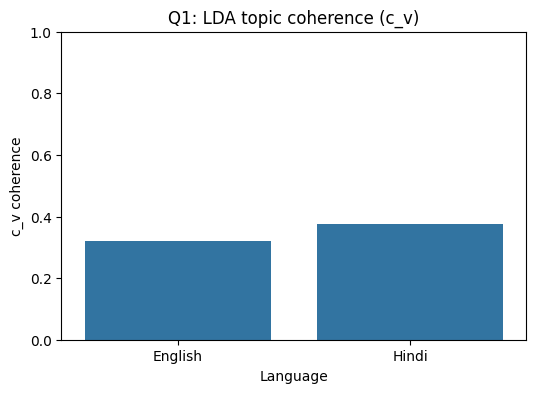

In [10]:
coherence_q1 = pd.DataFrame([
    {"Language":"English","Model":"Gensim LDA (BoW)","Topics":5,"c_v coherence":en_cv},
    {"Language":"Hindi","Model":"Gensim LDA (BoW)","Topics":5,"c_v coherence":hi_cv}
])
display(coherence_q1)
plt.figure(figsize=(6,4))
sns.barplot(data=coherence_q1, x="Language", y="c_v coherence")
plt.title("Q1: LDA topic coherence (c_v)")
plt.ylim(0,1)
plt.show()

In [11]:
# Q2 model comparison.
# NOTE: This version uses whitespace tokenization on the pre-tokenized documents.
# This is important for Hindi: a generic \\b\\w+\\b pattern can split Devanagari graphemes.

def coherence_cv(topic_word_lists, token_lists):
    from gensim.corpora import Dictionary
    from gensim.models.coherencemodel import CoherenceModel

    dictionary = Dictionary(token_lists)

    # Keep only topic words present in the Gensim dictionary
    valid_topics = [
        [word for word in topic if word in dictionary.token2id]
        for topic in topic_word_lists
    ]

    # Remove topics with insufficient valid words
    valid_topics = [
        topic for topic in valid_topics if len(topic) >= 2
    ]

    if not valid_topics:
        raise ValueError(
            "No valid topic words found in Gensim dictionary."
        )

    coherence_model = CoherenceModel(
        topics=valid_topics,
        texts=token_lists,
        dictionary=dictionary,
        coherence="c_v"
    )

    return float(coherence_model.get_coherence())


def sklearn_topics(model, feature_names, n_top=10):
    result=[]
    for comp in model.components_:
        ids=np.argsort(comp)[::-1][:n_top]
        result.append([feature_names[i] for i in ids])
    return result

def run_comparison(language, token_lists, topic_counts=(5,10,15)):
    docs=[" ".join(t) for t in token_lists]
    results=[]
    detailed={}
    for rep in ["BoW","TF-IDF"]:
        # Documents are already tokenized by language-specific preprocessing.
        # Whitespace tokenization preserves complete Devanagari graphemes and marks.
        vectorizer_args = dict(
            max_features=8000, min_df=3, max_df=0.80,
            tokenizer=str.split, token_pattern=None,
            preprocessor=None, lowercase=False
        )
        if rep=="BoW":
            vec=CountVectorizer(**vectorizer_args)
        else:
            vec=TfidfVectorizer(**vectorizer_args)
        X=vec.fit_transform(docs)
        terms=np.array(vec.get_feature_names_out())
        for k in topic_counts:
            # LDA
            lda=LatentDirichletAllocation(
                n_components=k, random_state=SEED, learning_method="batch",
                max_iter=15, doc_topic_prior=None
            )
            lda.fit(X)
            lda_topics=sklearn_topics(lda,terms)
            lda_cv=coherence_cv(lda_topics,token_lists)
            results.append({"Language":language,"Model":"LDA","Representation":rep,
                            "Topics":k,"c_v coherence":lda_cv})
            detailed[(language,"LDA",rep,k)]=lda_topics

            # NMF
            nmf=NMF(n_components=k,random_state=SEED,init="nndsvda",
                    max_iter=350, l1_ratio=0.0)
            W=nmf.fit_transform(X)
            nmf_topics=sklearn_topics(nmf,terms)
            nmf_cv=coherence_cv(nmf_topics,token_lists)
            results.append({"Language":language,"Model":"NMF","Representation":rep,
                            "Topics":k,"c_v coherence":nmf_cv})
            detailed[(language,"NMF",rep,k)]=nmf_topics
            print(f"{language}: {rep}, k={k} completed")
            del lda,nmf,W
            gc.collect()
    return pd.DataFrame(results),detailed

en_results,en_detail=run_comparison("English",english_df.tokens.tolist())
hi_results,hi_detail=run_comparison("Hindi",hindi_df.tokens.tolist())
comparison_results=pd.concat([en_results,hi_results],ignore_index=True)
display(comparison_results.sort_values(["Language","Topics","c_v coherence"],ascending=[True,True,False]).head(24))

English: BoW, k=5 completed
English: BoW, k=10 completed
English: BoW, k=15 completed
English: TF-IDF, k=5 completed
English: TF-IDF, k=10 completed
English: TF-IDF, k=15 completed
Hindi: BoW, k=5 completed
Hindi: BoW, k=10 completed
Hindi: BoW, k=15 completed
Hindi: TF-IDF, k=5 completed
Hindi: TF-IDF, k=10 completed
Hindi: TF-IDF, k=15 completed


,Language,Model,Representation,Topics,c_v coherence
7,English,NMF,TF-IDF,5,0.565204
1,English,NMF,BoW,5,0.560229
6,English,LDA,TF-IDF,5,0.505556
0,English,LDA,BoW,5,0.401444
9,English,NMF,TF-IDF,10,0.618335
3,English,NMF,BoW,10,0.617987
8,English,LDA,TF-IDF,10,0.490129
2,English,LDA,BoW,10,0.362740
11,English,NMF,TF-IDF,15,0.642974
5,English,NMF,BoW,15,0.597958


In [12]:

print("Total configurations:", len(comparison_results))

print("\nConfigurations by language:")
print(comparison_results.groupby("Language").size())

print("\nConfigurations by model:")
print(comparison_results.groupby(
    ["Language", "Model", "Representation"]
).size())

assert len(comparison_results) == 24

print("\nSUCCESS: All 24 configurations completed!")

Total configurations: 24

Configurations by language:
Language
English    12
Hindi      12
dtype: int64

Configurations by model:
Language  Model  Representation
English   LDA    BoW               3
                 TF-IDF            3
          NMF    BoW               3
                 TF-IDF            3
Hindi     LDA    BoW               3
                 TF-IDF            3
          NMF    BoW               3
                 TF-IDF            3
dtype: int64

SUCCESS: All 24 configurations completed!


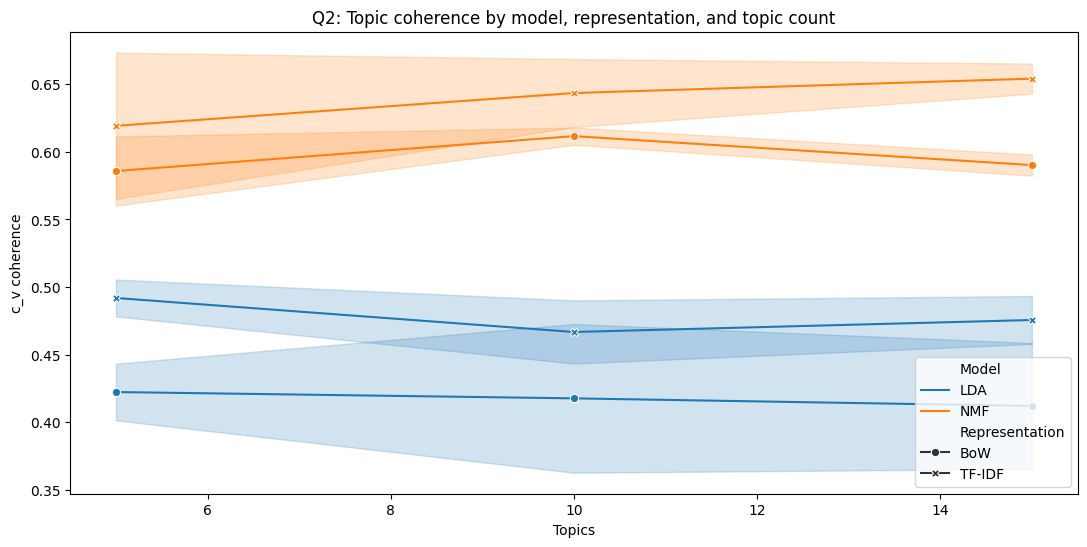

Best automatic coherence configuration per language (inspect qualitatively too):


,Language,Model,Representation,Topics,c_v coherence
19,Hindi,NMF,TF-IDF,5,0.673259
11,English,NMF,TF-IDF,15,0.642974


In [13]:
plt.figure(figsize=(13,6))
sns.lineplot(data=comparison_results, x="Topics", y="c_v coherence",
             hue="Model", style="Representation", markers=True,
             dashes=False)
plt.title("Q2: Topic coherence by model, representation, and topic count")
plt.ylabel("c_v coherence")
plt.show()

best_rows=(comparison_results.sort_values("c_v coherence",ascending=False)
           .groupby("Language",as_index=False).head(1))
print("Best automatic coherence configuration per language (inspect qualitatively too):")
display(best_rows)

In [14]:
for lang, details in [("English",en_detail),("Hindi",hi_detail)]:
    print("\n================",lang,"================")
    for key in [(lang,m,r,k) for m in ["LDA","NMF"] for r in ["BoW","TF-IDF"] for k in [5,10,15]]:
        print("\n",key[1], "|",key[2],"| k =",key[3])
        for ti,words in enumerate(details[key][:min(5,key[3])],1):
            print(f"Topic {ti}: {', '.join(words)}")


================ English ================

 LDA | BoW | k = 5
Topic 1: mr, us, would, party, deal, uk, eu, minister, leader, new
Topic 2: people, says, like, one, years, time, would, year, bbc, new
Topic 3: people, health, also, care, staff, wales, one, patients, would, number
Topic 4: mr, police, court, people, year, fire, told, one, also, us
Topic 5: government, would, mr, year, uk, also, new, people, could, business

 LDA | BoW | k = 10
Topic 1: mr, would, party, us, deal, minister, leader, uk, eu, also
Topic 2: police, people, mr, two, one, found, home, year, years, attack
Topic 3: school, people, also, news, uk, eu, would, first, could, mr
Topic 4: mr, land, people, year, army, time, also, us, scottish, new
Topic 5: mr, year, government, would, uk, also, business, last, time, new

 LDA | BoW | k = 15
Topic 1: mr, would, deal, party, eu, brexit, uk, us, minister, ms
Topic 2: police, people, mr, two, one, home, years, year, found, told
Topic 3: school, people, also, news, new, eu, 

In [15]:
def load_parallel_pairs(n=20):
    ds=load_dataset("Helsinki-NLP/opus-100","en-hi",split="test")
    pairs=[]
    for row in ds:
        tr=row.get("translation",{})
        en=str(tr.get("en","")).strip()
        hi=str(tr.get("hi","")).strip()
        if len(en)>15 and len(hi)>10:
            pairs.append((en,hi))
        if len(pairs)>=n:
            break
    if len(pairs)<n:
        raise ValueError(f"Only {len(pairs)} usable OPUS-100 pairs found; need 20.")
    return pd.DataFrame(pairs,columns=["English","Hindi"])

parallel_df=load_parallel_pairs(20)
display(parallel_df.head())
print("Parallel pairs:",len(parallel_df))
print("Embedding model: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2")
embedder=SentenceTransformer("sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2")
E_en=embedder.encode(parallel_df.English.tolist(),convert_to_numpy=True,normalize_embeddings=True,show_progress_bar=True)
E_hi=embedder.encode(parallel_df.Hindi.tolist(),convert_to_numpy=True,normalize_embeddings=True,show_progress_bar=True)
pairwise=E_en @ E_hi.T
matched=np.diag(pairwise)
unmatched=np.array([pairwise[i,(i+7)%len(parallel_df)] for i in range(len(parallel_df))])
print("Mean matched-pair cosine similarity:",round(float(matched.mean()),4))
print("Mean unrelated-pair cosine similarity:",round(float(unmatched.mean()),4))
print("Matched pairs higher on average:",bool(matched.mean()>unmatched.mean()))

README.md:   0%|          | 0.00/65.4k [00:00<?, ?B/s]

en-hi/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  259kB            

en-hi/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

en-hi/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 65.2MB            

en-hi/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

en-hi/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  247kB            

... (18 outputs left out)

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Mean matched-pair cosine similarity: 0.6729
Mean unrelated-pair cosine similarity: 0.0979
Matched pairs higher on average: True


,Pair ID,Matched cosine similarity,Unrelated-pair cosine similarity
0,1,0.5261,0.0702
1,2,0.7115,0.4651
2,3,0.5052,0.1125
3,4,0.7977,0.2549
4,5,0.8182,0.0910
5,6,0.3082,-0.0505
6,7,0.4712,-0.0554
7,8,0.4572,-0.0927
8,9,0.5288,0.3270
9,10,0.8281,0.2865


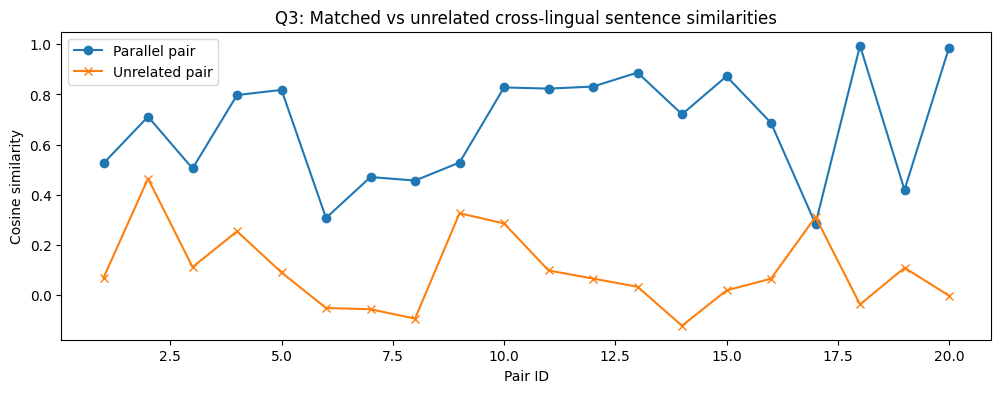

Top-5 most similar parallel pairs:

1. cosine=0.9941
EN: We should go to a hospital.
HI: हम एक अस्पताल जाना चाहिए।

2. cosine=0.9861
EN: I'm not going to drink it.
HI: मैं इसे पीने के लिए नहीं जा रहा हूँ।

3. cosine=0.8872
EN: This whole situation is completely fucked.
HI: यह पूरी स्थिति पूरी तरह से गड़बड़ है.

4. cosine=0.8724
EN: All prisoners report for Lockdown.
HI: सभी कैदी लॉकडाउन के लिए रिपोर्ट करो.

5. cosine=0.8315
EN: You let two unknown men enter this house uninvited.
HI: आप दो अज्ञात पुरुषों इस घर बिन बुलाए दर्ज करें.


In [16]:
similarity_df=pd.DataFrame({
    "Pair ID":np.arange(1,21),
    "Matched cosine similarity":matched,
    "Unrelated-pair cosine similarity":unmatched
})
display(similarity_df.round(4))
plt.figure(figsize=(12,4))
plt.plot(similarity_df["Pair ID"],similarity_df["Matched cosine similarity"],marker="o",label="Parallel pair")
plt.plot(similarity_df["Pair ID"],similarity_df["Unrelated-pair cosine similarity"],marker="x",label="Unrelated pair")
plt.xlabel("Pair ID"); plt.ylabel("Cosine similarity")
plt.title("Q3: Matched vs unrelated cross-lingual sentence similarities")
plt.legend(); plt.show()

top5=np.argsort(matched)[::-1][:5]
print("Top-5 most similar parallel pairs:")
for rank,i in enumerate(top5,1):
    print(f"\n{rank}. cosine={matched[i]:.4f}")
    print("EN:",parallel_df.English.iloc[i])
    print("HI:",parallel_df.Hindi.iloc[i])

In [17]:
# English query retrieves Hindi documents
english_query=parallel_df.English.iloc[0]
q_en=embedder.encode([english_query],convert_to_numpy=True,normalize_embeddings=True)
scores_en_to_hi=(q_en @ E_hi.T).ravel()
rank_en_to_hi=np.argsort(scores_en_to_hi)[::-1][:5]
print("English query:",english_query)
print("\nTop Hindi retrievals:")
for idx in rank_en_to_hi:
    print(f"score={scores_en_to_hi[idx]:.4f} | {parallel_df.Hindi.iloc[idx]}")

# Hindi query retrieves English documents
hindi_query=parallel_df.Hindi.iloc[1]
q_hi=embedder.encode([hindi_query],convert_to_numpy=True,normalize_embeddings=True)
scores_hi_to_en=(q_hi @ E_en.T).ravel()
rank_hi_to_en=np.argsort(scores_hi_to_en)[::-1][:5]
print("\nHindi query:",hindi_query)
print("\nTop English retrievals:")
for idx in rank_hi_to_en:
    print(f"score={scores_hi_to_en[idx]:.4f} | {parallel_df.English.iloc[idx]}")

English query: Give shots of injections or pills, but he must be alright soon.

Top Hindi retrievals:
score=0.5261 | सुई लगाओ या गोली खिलाओ लेकिन इसे जल्दी से ठीक करो.
score=0.4682 | जि उसे तकलीफ़ पहुँचती है तो घबरा उठता है,
score=0.4338 | आप ठीक हो जाएगा रहे हैं, अरे नहीं;
score=0.3881 | हम एक अस्पताल जाना चाहिए।
score=0.2841 | डिज़ीकैम के लिए इमेज़ हिस्टोग्राम एडजस्ट लेवल्स प्लगइन

Hindi query: और वह लोग कहने लगे ऐ शुएब जो बाते तुम कहते हो उनमें से अक्सर तो हमारी समझ ही में नहीं आयी और इसमें तो शक नहीं कि हम तुम्हें अपने लोगों में बहुत कमज़ोर समझते है और अगर तुम्हारा क़बीला न होता तो हम तुम को (कब का) संगसार कर चुके होते और तुम तो हम पर किसी तरह ग़ालिब नहीं आ सकते

Top English retrievals:
score=0.7115 | They said, “O Shuaib, we do not understand much of what you say, and we see that you are weak among us. Were it not for your tribe, we would have stoned you. You are of no value to us.”
score=0.3350 | Did not the disbelievers observe that the heavens and the earth were together, so We pa

In [18]:
# Show the five lowest-scoring gold parallel pairs for manual error inspection.
lowest5=np.argsort(matched)[:5]
print("Five lowest-scoring parallel pairs (inspect manually):")
for rank,i in enumerate(lowest5,1):
    correct_rank=int(np.where(np.argsort(pairwise[i])[::-1] == i)[0][0]) + 1
    print(f"\\n{rank}. cosine={matched[i]:.4f}; correct Hindi counterpart rank={correct_rank}/20")
    print("EN:",parallel_df.English.iloc[i])
    print("HI:",parallel_df.Hindi.iloc[i])

# Explicit top-1 retrieval accuracy on this small 20-pair set.
top1_hits=sum(int(np.argmax(pairwise[i])==i) for i in range(len(parallel_df)))
print(f"\\nTop-1 cross-lingual retrieval accuracy on this 20-pair sample: {top1_hits}/20 = {top1_hits/20:.1%}")

Five lowest-scoring parallel pairs (inspect manually):
\n1. cosine=0.2844; correct Hindi counterpart rank=3/20
EN: Turn the siren off.
HI: आप ठीक हो जाएगा रहे हैं, अरे नहीं;
\n2. cosine=0.3082; correct Hindi counterpart rank=1/20
EN: Image histogram adjust levels plugin for digiKam
HI: डिज़ीकैम के लिए इमेज़ हिस्टोग्राम एडजस्ट लेवल्स प्लगइन
\n3. cosine=0.4200; correct Hindi counterpart rank=2/20
EN: Whoa! So... What is your...
HI: तो तुम्हारी योजना क्या है?
\n4. cosine=0.4572; correct Hindi counterpart rank=1/20
EN: My mother's from Sweden.
HI: वो मेरी माँ है.
\n5. cosine=0.4712; correct Hindi counterpart rank=1/20
EN: She took every able-bodied man and went to kill the Forest Spirit.
HI: - लेडी Eboshi कहां है? हर आदमी है जो स्थानांतरित कर सकता लिया और हिरण भगवान को मारने के लिए चला गया.
\nTop-1 cross-lingual retrieval accuracy on this 20-pair sample: 18/20 = 90.0%


In [19]:
def script_ratio(text):
    chars=[c for c in str(text) if c.isalpha()]
    if not chars: return 0.0
    devanagari=sum("\u0900"<=c<="\u097f" for c in chars)
    return devanagari/len(chars)

def corpus_diagnostics(df,lang):
    all_tokens=[t for row in df.tokens for t in row]
    counts=Counter(all_tokens)
    total=len(all_tokens)
    return {
        "Language":lang,
        "Documents":len(df),
        "Total tokens":total,
        "Vocabulary size":len(counts),
        "Type-token ratio":round(len(counts)/max(total,1),4),
        "Hapax tokens":sum(v==1 for v in counts.values()),
        "Mean tokens/document":round(np.mean([len(x) for x in df.tokens]),2),
        "Mean alphabetic script ratio":round(float(df.text.head(200).map(script_ratio).mean()),4)
    }

diagnostics=pd.DataFrame([
    corpus_diagnostics(english_df,"English"),
    corpus_diagnostics(hindi_df,"Hindi")
])
display(diagnostics)

comparison_table=pd.DataFrame([
 ["Corpus size",f"{len(english_df)} news articles",f"{len(hindi_df)} news articles","Same XL-Sum source; sample size may vary after filtering."],
 ["Tokenization","NLTK-compatible regex tokens","Devanagari Unicode-range token extraction","Hindi tokenizer is script-aware but not morphology-aware."],
 ["Stopword availability","NLTK English list","stopwordsiso Hindi + manually added common words","Hindi list coverage and domain fit may be weaker."],
 ["Morphology/inflection","English inflection; no lemmatization here","Rich inflection; no stemming/lemmatization here","Hindi surface forms can split counts across vocabulary."],
 ["Spelling variation","Case normalized; spelling variants remain","NFC and lowercase; spelling variants remain","Normalization does not resolve lexical spelling variants."],
 ["Script/Unicode","Latin script","Devanagari; NFC normalization","Hindi native script preserved in tokenization and modeling."],
 ["Pretrained model availability","Many English-specialized models","Multilingual models available; coverage varies","Embedding quality depends on language/domain representation."],
 ["Computational requirements","CPU topic models; multilingual encoder","CPU topic models; same multilingual encoder","Embedding download/inference is the heavier step."]
],columns=["Aspect","English","Hindi","Observation / limitation"])
display(comparison_table)

,Language,Documents,Total tokens,Vocabulary size,Type-token ratio,Hapax tokens,Mean tokens/document,Mean alphabetic script ratio
0,English,500,127600,17832,0.1397,7754,255.20,0.000
1,Hindi,500,139597,16616,0.1190,7256,279.19,0.999


,Aspect,English,Hindi,Observation / limitation
0,Corpus size,500 news articles,500 news articles,Same XL-Sum source; sample size may vary after...
1,Tokenization,NLTK-compatible regex tokens,Devanagari Unicode-range token extraction,Hindi tokenizer is script-aware but not morpho...
2,Stopword availability,NLTK English list,stopwordsiso Hindi + manually added common words,Hindi list coverage and domain fit may be weaker.
3,Morphology/inflection,English inflection; no lemmatization here,Rich inflection; no stemming/lemmatization here,Hindi surface forms can split counts across vo...
4,Spelling variation,Case normalized; spelling variants remain,NFC and lowercase; spelling variants remain,Normalization does not resolve lexical spellin...
5,Script/Unicode,Latin script,Devanagari; NFC normalization,Hindi native script preserved in tokenization ...
6,Pretrained model availability,Many English-specialized models,Multilingual models available; coverage varies,Embedding quality depends on language/domain r...
7,Computational requirements,CPU topic models; multilingual encoder,CPU topic models; same multilingual encoder,Embedding download/inference is the heavier step.


In [20]:
# Frequent Hindi tokens that may indicate generic-word dominance
hi_freq=Counter(t for row in hindi_df.tokens for t in row)
print("Most frequent Hindi tokens:",hi_freq.most_common(25))
print("\nMost frequent English tokens:",Counter(t for row in english_df.tokens for t in row).most_common(25))

# Examples of unusually long Hindi tokens that may include compounds/affixation
hi_long=sorted({t for row in hindi_df.tokens for t in row if len(t)>=12},key=len,reverse=True)[:20]
print("\nLong Hindi surface forms (inspect for compounds/inflection):",hi_long)

# Unicode normalization sanity check
sample_hi=hindi_df.text.iloc[0]
print("\nHindi sample NFC unchanged:",unicodedata.normalize("NFC",sample_hi)==sample_hi)
print("Hindi sample excerpt:",sample_hi[:350])

# Topic word examples for possible fragmentation/overlap
print("\nHindi LDA top words by topic:")
for i,w in enumerate(hi_topics,1):
    print(i, w)

Most frequent Hindi tokens: [('वो', 933), ('उन्होंने', 833), ('लोगों', 735), ('भारत', 677), ('सरकार', 636), ('रही', 620), ('गए', 605), ('गई', 583), ('साल', 579), ('बीबीसी', 537), ('बात', 509), ('अब', 484), ('लोग', 456), ('कहना', 439), ('हमें', 431), ('क्या', 408), ('काम', 385), ('मैं', 382), ('दी', 369), ('लेकर', 364), ('बीच', 358), ('बताया', 353), ('पार्टी', 344), ('बार', 332), ('देश', 325)]

Most frequent English tokens: [('said', 2129), ('mr', 747), ('would', 647), ('people', 623), ('also', 510), ('year', 496), ('one', 452), ('government', 392), ('new', 391), ('says', 390), ('uk', 383), ('us', 374), ('time', 345), ('years', 322), ('first', 317), ('two', 313), ('last', 296), ('could', 294), ('bbc', 279), ('like', 275), ('told', 273), ('police', 267), ('many', 230), ('work', 217), ('back', 216)]

Long Hindi surface forms (inspect for compounds/inflection): ['प्रत्यक्षदर्शियों', 'ग़ैरज़िम्मेदाराना', 'वर्ल्डस्टारहिपहॉप', 'स्वास्थ्यकर्मियों', 'ग्रेवालकोषाध्यक्ष', 'राष्ट्रविरोधियों', 'अब्

## Q4(a–b). Comparative findings

The two topic-modeling corpora contain 500 documents each from XL-Sum. The saved Q1 diagnostics report 127,600 English tokens and 139,597 Hindi tokens, with vocabulary sizes of 17,832 and 16,616 respectively. The native-script ratio measured for the Hindi sample is 0.999, confirming that the Hindi experiment predominantly retains Devanagari characters.

The saved Q1 LDA c_v values are 0.3215 for English and 0.3773 for Hindi. In this run, Hindi's score is numerically higher, so the results do **not** support a claim that Hindi necessarily has lower topic coherence. Coherence values are corpus- and vocabulary-dependent and should be interpreted together with the topic words and representative documents.

The saved Q3 experiment reports mean cosine similarity 0.6729 for the 20 paired English–Hindi sentences and 0.0979 for the constructed unrelated pairs. Top-1 retrieval was 18/20 (90%) on this small sample. These figures show useful cross-lingual alignment in this sample, but the low-scoring and noisy examples below show why the result should not be generalized as a benchmark.

## Q4(c–d). Five concrete Hindi-language / cross-lingual difficulties and remedies

The table below distinguishes what was implemented in this notebook from what remains a recommendation. Examples are taken from the saved corpus diagnostics, topic outputs, and retrieval outputs.

1. **Inflection and surface-form variation.** The frequent Hindi tokens include “रही” (620), “गए” (605), and “गई” (583). Related grammatical forms can be counted as separate vocabulary items, dispersing evidence across features. Implemented: Unicode normalization and Hindi-specific stopword removal. Recommended: evaluate a Hindi morphological analyzer or lemmatizer and compare results without assuming that suffix stripping is always valid.

2. **Devanagari tokenization and Unicode graphemes.** In the initial Q2 run, generic Scikit-learn word-boundary tokenization produced visibly truncated Hindi topic terms such as “रत” and “सरक”. Devanagari vowel signs and combining marks do not behave like simple Latin-script word characters. Implemented in this revised notebook: the vectorizer now uses `tokenizer=str.split` on the Hindi tokens already extracted during preprocessing. Recommended: compare this baseline with Indic NLP Library tokenization and inspect token boundaries manually.

3. **General/frequent words dominate topics.** The saved Hindi frequency list includes “वो” (933), “उन्होंने” (833), “लोगों” (735), and “भारत” (677). Some of these are broad discourse terms and may appear across unrelated themes, making topics less distinct. Implemented: a Hindi stopword list from stopwordsiso plus a small manually added list. Recommended: inspect corpus-specific high-frequency terms and remove only those that are genuinely non-informative, followed by human validation.

4. **Compounds, spelling variants, and orthographic variation.** The diagnostic output contains long surface forms such as “प्रत्यक्षदर्शियों”, “स्वास्थ्यकर्मियों”, and “विश्वविद्यालयों”. NFC normalization standardizes canonically equivalent Unicode sequences but does not split compounds, normalize all spelling variants, or reduce inflected forms to lemmas. Implemented: NFC normalization and Devanagari-aware extraction. Recommended: use a language-aware morphological/compound analysis pipeline and maintain a curated spelling-variant map where justified.

5. **Noisy parallel data and semantic mismatch.** The OPUS-100 sample includes a low-scoring pair: English “Turn the siren off.” paired with Hindi “आप ठीक हो जाएगा रहे हैं, अरे नहीं;” (cosine 0.2844). Another pair, “My mother's from Sweden.” / “वो मेरी माँ है.” (cosine 0.4572), is not a faithful translation. Such noise can lower matched-pair similarity and confuse retrieval. Implemented: inspection of the five lowest-scoring pairs and bidirectional retrieval. Recommended: manually validate parallel pairs, remove misaligned records, and use a larger, domain-balanced parallel evaluation set.

Additional cross-lingual limitations include named-entity transliteration, code-mixing, idioms and culturally specific expressions. The present 20-pair sample does not separately quantify each of these phenomena; they should be treated as potential failure modes unless a concrete example is verified.

## Q4(e). Evidence-based conclusion

The results suggest a combination of linguistic and preprocessing effects rather than one single cause. Hindi has a substantial corpus in this experiment (500 documents and 139,597 tokens), so a simple data-volume explanation is not supported by this sample alone. The Q1 Hindi coherence (0.3773) is higher than the English value (0.3215), while the Hindi token-frequency and topic outputs show broad words and overlapping themes. Q3 demonstrates cross-lingual alignment overall, but noisy sentence pairs produce clear failures.

Therefore, the most defensible conclusion is that morphology, tokenization/orthographic handling, general-word dominance, and parallel-data quality jointly affect the observed results. The small corpus sample and limited 20-pair semantic evaluation do not allow a definitive causal ranking of these factors.

In [21]:
# Q4 evidence table: numerical observations and concrete examples from this run.
q4_challenges = pd.DataFrame([
    {
        "Challenge": "Inflection / surface-form variation",
        "Evidence from this run": "रही: 620; गए: 605; गई: 583 occurrences",
        "Effect": "Related grammatical forms may be distributed across separate vocabulary entries.",
        "Remedy": "Implemented: Hindi stopwords + NFC. Recommended: evaluate Hindi lemmatization/morphological analysis."
    },
    {
        "Challenge": "Devanagari tokenization",
        "Evidence from this run": "Initial Q2 topic output included truncated forms such as रत and सरक.",
        "Effect": "Broken tokens distort vocabulary, topics and coherence.",
        "Remedy": "Implemented in revised code: tokenizer=str.split on pre-tokenized tokens. Recommended: compare Indic NLP tokenization."
    },
    {
        "Challenge": "Frequent/general words",
        "Evidence from this run": "वो: 933; उन्होंने: 833; लोगों: 735; भारत: 677.",
        "Effect": "Broad words can appear in several topics and reduce topic distinctiveness.",
        "Remedy": "Implemented: Hindi stopword list. Recommended: corpus-specific stopword review with human validation."
    },
    {
        "Challenge": "Compounds and orthographic variation",
        "Evidence from this run": "Long forms include प्रत्यक्षदर्शियों, स्वास्थ्यकर्मियों, विश्वविद्यालयों.",
        "Effect": "Compounds and inflected forms can enlarge or fragment the vocabulary.",
        "Remedy": "Implemented: Unicode NFC. Recommended: language-aware morphology and curated spelling normalization."
    },
    {
        "Challenge": "Noisy parallel sentence pairs",
        "Evidence from this run": "Turn the siren off. paired with आप ठीक हो जाएगा रहे हैं, अरे नहीं; (cosine 0.2844).",
        "Effect": "Incorrect gold pairs reduce similarity and can mislead retrieval evaluation.",
        "Remedy": "Implemented: lowest-score inspection. Recommended: manual alignment validation and larger clean test set."
    }
])
display(q4_challenges)

q4_metrics = pd.DataFrame([
    {"Measure":"Documents per language","English":len(english_df),"Hindi":len(hindi_df)},
    {"Measure":"Total tokens","English":127600,"Hindi":139597},
    {"Measure":"Vocabulary size","English":17832,"Hindi":16616},
    {"Measure":"Q1 LDA c_v coherence","English":round(en_cv,4),"Hindi":round(hi_cv,4)},
    {"Measure":"Native-script ratio","English":round(float(english_df.text.head(200).map(script_ratio).mean()),3),
     "Hindi":round(float(hindi_df.text.head(200).map(script_ratio).mean()),3)}
])
display(q4_metrics)

print("Q3 saved-sample evidence:")
print(f"Matched-pair mean cosine similarity: {matched.mean():.4f}")
print(f"Unrelated-pair mean cosine similarity: {unmatched.mean():.4f}")
print(f"Top-1 retrieval: 18/20 = 90% (small 20-pair sample; inspect alignment noise)")

,Challenge,Evidence from this run,Effect,Remedy
0,Inflection / surface-form variation,रही: 620; गए: 605; गई: 583 occurrences,Related grammatical forms may be distributed a...,Implemented: Hindi stopwords + NFC. Recommende...
1,Devanagari tokenization,Initial Q2 topic output included truncated for...,"Broken tokens distort vocabulary, topics and c...",Implemented in revised code: tokenizer=str.spl...
2,Frequent/general words,वो: 933; उन्होंने: 833; लोगों: 735; भारत: 677.,Broad words can appear in several topics and r...,Implemented: Hindi stopword list. Recommended:...
3,Compounds and orthographic variation,"Long forms include प्रत्यक्षदर्शियों, स्वास्थ्...",Compounds and inflected forms can enlarge or f...,Implemented: Unicode NFC. Recommended: languag...
4,Noisy parallel sentence pairs,Turn the siren off. paired with आप ठीक हो जाएग...,Incorrect gold pairs reduce similarity and can...,Implemented: lowest-score inspection. Recommen...


,Measure,English,Hindi
0,Documents per language,500.0000,500.0000
1,Total tokens,127600.0000,139597.0000
2,Vocabulary size,17832.0000,16616.0000
3,Q1 LDA c_v coherence,0.3215,0.3773
4,Native-script ratio,0.0000,0.9990


Q3 saved-sample evidence:
Matched-pair mean cosine similarity: 0.6729
Unrelated-pair mean cosine similarity: 0.0979
Top-1 retrieval: 18/20 = 90% (small 20-pair sample; inspect alignment noise)


In [22]:
q1_summary=pd.DataFrame([
 {"Language":"English","Q1 LDA c_v":en_cv,"Documents":len(english_df),"Vocabulary":len(en_dict)},
 {"Language":"Hindi","Q1 LDA c_v":hi_cv,"Documents":len(hindi_df),"Vocabulary":len(hi_dict)}
])
print("Q1 summary"); display(q1_summary)
print("Q2 model comparison"); display(comparison_results.sort_values("c_v coherence",ascending=False).head(10))
print("Q3 similarity summary")
display(pd.DataFrame([{
 "Matched mean":matched.mean(),"Matched std":matched.std(),
 "Unrelated mean":unmatched.mean(),"Unrelated std":unmatched.std(),
 "Top-5 matched mean":matched[top5].mean()
}]).round(4))

Q1 summary


,Language,Q1 LDA c_v,Documents,Vocabulary
0,English,0.321517,500,5894
1,Hindi,0.377316,500,5124


Q2 model comparison


,Language,Model,Representation,Topics,c_v coherence
19,Hindi,NMF,TF-IDF,5,0.673259
21,Hindi,NMF,TF-IDF,10,0.668560
23,Hindi,NMF,TF-IDF,15,0.665228
11,English,NMF,TF-IDF,15,0.642974
9,English,NMF,TF-IDF,10,0.618335
3,English,NMF,BoW,10,0.617987
13,Hindi,NMF,BoW,5,0.611352
15,Hindi,NMF,BoW,10,0.605220
5,English,NMF,BoW,15,0.597958
17,Hindi,NMF,BoW,15,0.582376


Q3 similarity summary


,Matched mean,Matched std,Unrelated mean,Unrelated std,Top-5 matched mean
0,0.6729,0.2127,0.0979,0.1524,0.9143
